# 05. Training and Optimization in Deep Learning
## A complete practical guide with PyTorch

This notebook explains how neural networks learn, how optimization algorithms update parameters, and how to diagnose and improve training.

### Learning objectives
- Understand the full training loop: forward pass, loss, backpropagation, and optimizer update.
- Derive gradient descent and understand learning-rate behavior.
- Compare batch, stochastic, and mini-batch gradient descent.
- Compare SGD, Momentum, RMSprop, Adam, and AdamW.
- Interpret training and validation curves.
- Diagnose underfitting, overfitting, unstable gradients, and data leakage.
- Apply learning-rate schedules, weight decay, dropout, gradient clipping, and early stopping.
- Evaluate models with metrics beyond accuracy.
- Save checkpoints and run controlled experiments.

The notebook uses a synthetic nonlinear classification dataset so the experiments can run without downloading data. Synthetic experiments teach concepts, but real projects also need careful data splitting and domain-specific evaluation.

## 1. The training process

For input \(x\), a neural network with parameters \(\theta\) predicts:

$$
\hat{y} = f_\theta(x)
$$

A loss function measures disagreement between predictions and targets:

$$
\mathcal{L}(\theta) = \frac{1}{N}\sum_{i=1}^{N}
\ell(f_\theta(x_i), y_i)
$$

Each training step typically performs these operations:

1. **Forward pass:** compute predictions.
2. **Loss calculation:** compare predictions with targets.
3. **Backpropagation:** compute gradients of the loss with respect to parameters.
4. **Optimizer update:** use gradients to change parameters.
5. **Repeat:** process more mini-batches and epochs.
6. **Validation:** measure performance on data not used for parameter updates.

**Backpropagation computes gradients; the optimizer uses those gradients to update parameters.**

## 2. Gradient descent and the learning rate

Vanilla gradient descent updates parameters according to:

$$
\theta_{t+1} = \theta_t - \eta \nabla_\theta \mathcal{L}(\theta_t)
$$

Here, \(\eta\) is the learning rate. The gradient points toward the direction of steepest local increase, so gradient descent moves in the opposite direction.

Consider:

$$
\mathcal{L}(w) = (w-3)^2,\qquad
\frac{d\mathcal{L}}{dw} = 2(w-3)
$$

The minimum is at \(w=3\). A small learning rate can be stable but slow; a rate that is too large can overshoot, oscillate, or diverge.

PyTorch: 2.5.1+cu121
Device: cuda


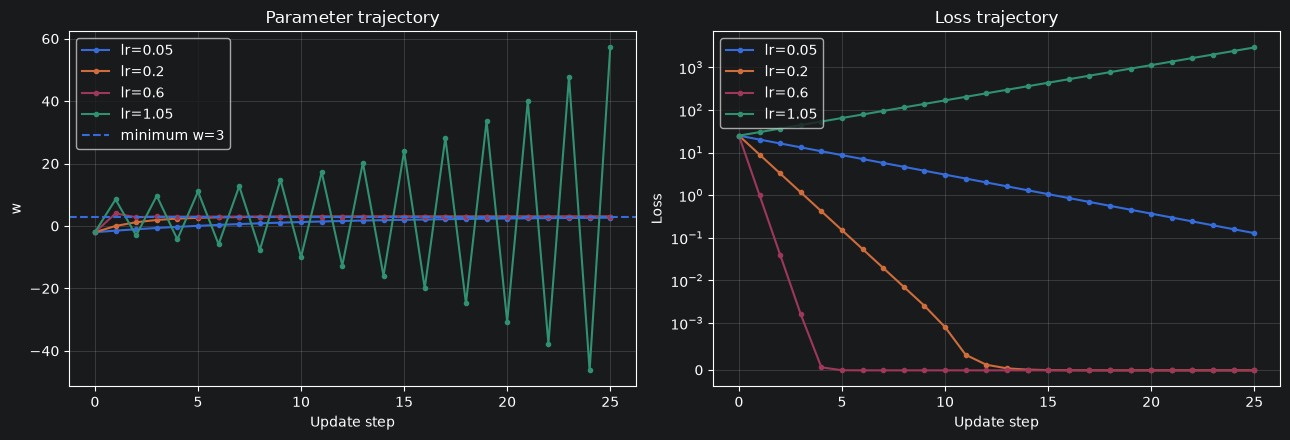

In [1]:
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)

def gradient_descent_1d(w0, learning_rate, steps=30):
    # Optimize L(w) = (w - 3)^2 and record each parameter/loss pair.
    w = float(w0)
    history = [(w, (w - 3) ** 2)]
    for _ in range(steps):
        grad = 2 * (w - 3)
        w = w - learning_rate * grad
        history.append((w, (w - 3) ** 2))
    return np.array(history)

rates = [0.05, 0.2, 0.6, 1.05]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for lr in rates:
    hist = gradient_descent_1d(-2, lr, steps=25)
    axes[0].plot(hist[:, 0], marker=".", label=f"lr={lr}")
    axes[1].plot(hist[:, 1], marker=".", label=f"lr={lr}")
axes[0].axhline(3, linestyle="--", label="minimum w=3")
axes[0].set(title="Parameter trajectory", xlabel="Update step", ylabel="w")
axes[1].set(title="Loss trajectory", xlabel="Update step", ylabel="Loss")
axes[1].set_yscale("symlog", linthresh=1e-3)
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 3. Epochs, batches, and iterations

- **Sample:** one example.
- **Batch / mini-batch:** a subset of examples processed together.
- **Iteration / optimizer step:** one parameter update.
- **Epoch:** one complete pass through the training set.

For \(N\) examples and batch size \(B\), the number of batches per epoch is usually:

$$
\text{steps per epoch} = \left\lceil \frac{N}{B} \right\rceil
$$

With `drop_last=True`, an incomplete final batch is discarded. Shuffling training examples each epoch helps avoid repeatedly processing them in a fixed order.

In [2]:
# Inspect how DataLoader divides a dataset into mini-batches.
x_demo = torch.arange(23, dtype=torch.float32).reshape(-1, 1)
y_demo = (x_demo % 2 == 0).float()
demo_loader = DataLoader(TensorDataset(x_demo, y_demo), batch_size=5,
                          shuffle=True, drop_last=False)
print("Samples:", len(x_demo), "| batches per epoch:", len(demo_loader))
for i, (xb, yb) in enumerate(demo_loader):
    print(f"Batch {i + 1}: X={tuple(xb.shape)}, y={tuple(yb.shape)}")

Samples: 23 | batches per epoch: 5
Batch 1: X=(5, 1), y=(5, 1)
Batch 2: X=(5, 1), y=(5, 1)
Batch 3: X=(5, 1), y=(5, 1)
Batch 4: X=(5, 1), y=(5, 1)
Batch 5: X=(3, 1), y=(3, 1)


## 4. Batch, stochastic, and mini-batch gradient descent

- **Batch gradient descent:** uses all training examples for each update. The gradient can be stable, but updates are expensive on large datasets.
- **Stochastic gradient descent (SGD):** uses one example per update. Updates are cheap but noisy.
- **Mini-batch gradient descent:** uses a subset of examples. This is the standard approach in deep learning.

For a mini-batch \(\mathcal{B}\), the gradient estimate is:

$$
g_t = \frac{1}{|\mathcal{B}|}
\sum_{i\in\mathcal{B}}\nabla_\theta \ell_i(\theta_t)
$$

Because batches differ, the loss does not have to decrease at every individual step.

## 5. Create a nonlinear classification dataset

We will predict whether a point lies inside or outside a noisy circular boundary. A linear model cannot represent this boundary well, while a multilayer perceptron can learn a nonlinear decision surface.

- **Training set:** used for gradient updates.
- **Validation set:** used for model selection and hyperparameter tuning.
- **Test set:** held back until final evaluation.

Repeatedly tuning against the test set leaks information from it into model selection.

Train: torch.Size([1680, 2]) torch.Size([1680, 1])
Validation: torch.Size([360, 2]) torch.Size([360, 1])
Test: torch.Size([360, 2]) torch.Size([360, 1])


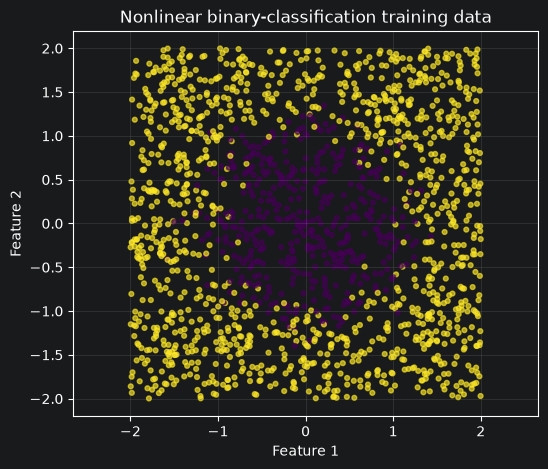

In [3]:
rng = np.random.default_rng(SEED)
n_samples = 2400
X_np = rng.uniform(-2.0, 2.0, size=(n_samples, 2)).astype(np.float32)
radius = np.sqrt(X_np[:, 0] ** 2 + X_np[:, 1] ** 2)
noise = rng.normal(0.0, 0.18, size=n_samples)
y_np = ((radius + noise) > 1.15).astype(np.float32).reshape(-1, 1)

indices = rng.permutation(n_samples)
train_end, val_end = int(0.70 * n_samples), int(0.85 * n_samples)
train_idx, val_idx, test_idx = indices[:train_end], indices[train_end:val_end], indices[val_end:]

X_train, y_train = torch.tensor(X_np[train_idx]), torch.tensor(y_np[train_idx])
X_val, y_val = torch.tensor(X_np[val_idx]), torch.tensor(y_np[val_idx])
X_test, y_test = torch.tensor(X_np[test_idx]), torch.tensor(y_np[test_idx])

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

plt.figure(figsize=(6, 5))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train.squeeze(), s=12, alpha=0.65)
plt.title("Nonlinear binary-classification training data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.axis("equal")
plt.grid(True, alpha=0.2)
plt.show()

## 6. Model outputs, logits, and binary cross-entropy

For binary classification, a model can output a **logit** \(z\), an unrestricted real number. Sigmoid converts it to a probability:

$$
p(y=1\mid x) = \sigma(z) = \frac{1}{1+e^{-z}}
$$

Binary cross-entropy is:

$$
\ell(y,z) = -\left[
y\log \sigma(z) + (1-y)\log(1-\sigma(z))
\right]
$$

In PyTorch, `nn.BCEWithLogitsLoss` combines sigmoid and binary cross-entropy in a numerically stable implementation. Therefore, the model should return logits, not probabilities, when using this loss.

In [4]:
class MLP(nn.Module):
    # A small multilayer perceptron for binary classification.
    def __init__(self, input_dim=2, hidden_dim=32, dropout=0.0):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(hidden_dim, 1)  # One logit per example.
        )

    def forward(self, x):
        return self.network(x)

criterion = nn.BCEWithLogitsLoss()
model = MLP().to(device)
print(model)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

MLP(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=32, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Trainable parameters: 1185


## 7. Evaluation helper and the training loop

The standard PyTorch training step is:

1. `model.train()` enables training behavior such as dropout.
2. `optimizer.zero_grad()` clears gradients from the previous step.
3. The forward pass computes logits.
4. The loss compares logits with labels.
5. `loss.backward()` calculates gradients.
6. `optimizer.step()` updates parameters.

PyTorch accumulates gradients by default, so omitting `zero_grad()` changes the intended update. During evaluation, use `model.eval()` and `torch.no_grad()` so dropout is disabled and gradients are not tracked.

In [5]:
def evaluate_loss_and_accuracy(model, loader, criterion, device):
    # Evaluate average loss and accuracy without computing gradients.
    model.eval()
    total_loss, total_correct, total_examples = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            n = xb.size(0)
            total_loss += loss.item() * n
            predictions = (torch.sigmoid(logits) >= 0.5).float()
            total_correct += (predictions == yb).sum().item()
            total_examples += n
    return total_loss / total_examples, total_correct / total_examples


def train_model(model, train_loader, val_loader, criterion, optimizer,
                epochs=50, device=device, scheduler=None, grad_clip_norm=None):
    # Fit the model and store training/validation metrics for every epoch.
    history = {k: [] for k in [
        "train_loss", "val_loss", "train_accuracy", "val_accuracy", "learning_rate"
    ]}
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()

            # Optional stabilization for unusually large gradients.
            if grad_clip_norm is not None:
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=grad_clip_norm)

            optimizer.step()

        train_loss, train_acc = evaluate_loss_and_accuracy(
            model, train_loader, criterion, device
        )
        val_loss, val_acc = evaluate_loss_and_accuracy(
            model, val_loader, criterion, device
        )
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)
        history["learning_rate"].append(optimizer.param_groups[0]["lr"])

        if scheduler is not None:
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_loss)
            else:
                scheduler.step()

        if epoch == 0 or (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch + 1:03d}/{epochs} | "
                  f"train loss={train_loss:.4f} | val loss={val_loss:.4f} | "
                  f"train acc={train_acc:.3f} | val acc={val_acc:.3f}")
    return history


batch_size = 64
train_loader = DataLoader(TensorDataset(X_train, y_train),
                          batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val),
                        batch_size=256, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test, y_test),
                         batch_size=256, shuffle=False)

torch.manual_seed(SEED)
model = MLP().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
history = train_model(model, train_loader, val_loader, criterion,
                      optimizer, epochs=60, device=device)

Epoch 001/60 | train loss=0.5584 | val loss=0.5647 | train acc=0.731 | val acc=0.731
Epoch 010/60 | train loss=0.1842 | val loss=0.2057 | train acc=0.936 | val acc=0.919
Epoch 020/60 | train loss=0.1376 | val loss=0.1789 | train acc=0.943 | val acc=0.914
Epoch 030/60 | train loss=0.1357 | val loss=0.1840 | train acc=0.944 | val acc=0.906
Epoch 040/60 | train loss=0.1329 | val loss=0.1806 | train acc=0.942 | val acc=0.919
Epoch 050/60 | train loss=0.1330 | val loss=0.1843 | train acc=0.946 | val acc=0.900
Epoch 060/60 | train loss=0.1311 | val loss=0.1811 | train acc=0.945 | val acc=0.906


## 8. Plot and interpret learning curves

Training curves are diagnostic tools.

- **Both losses remain high:** possible underfitting, insufficient training, or an optimization problem.
- **Training loss decreases while validation loss rises:** a common overfitting pattern.
- **Loss oscillates heavily:** learning rate may be too high, batches may be noisy, or the data may contain problems.
- **Both losses decrease and remain close:** often a healthy pattern, but not proof of generalization.
- **Validation loss improves while accuracy barely changes:** predicted probabilities can improve even when thresholded labels remain unchanged.

The lowest validation loss and highest validation accuracy may occur at different epochs.

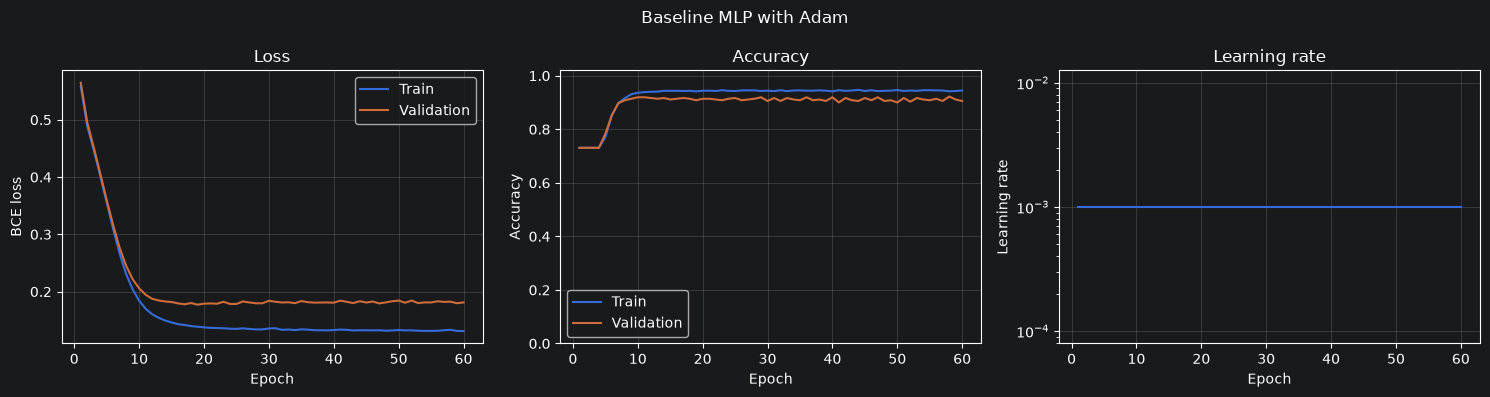

In [6]:
def plot_history(history, title="Training history"):
    # Visualize loss, accuracy, and learning-rate trends.
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["val_loss"], label="Validation")
    axes[0].set(title="Loss", xlabel="Epoch", ylabel="BCE loss")
    axes[0].legend()
    axes[1].plot(epochs, history["train_accuracy"], label="Train")
    axes[1].plot(epochs, history["val_accuracy"], label="Validation")
    axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.02))
    axes[1].legend()
    axes[2].plot(epochs, history["learning_rate"])
    axes[2].set(title="Learning rate", xlabel="Epoch", ylabel="Learning rate")
    axes[2].set_yscale("log")
    for ax in axes:
        ax.grid(True, alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history, "Baseline MLP with Adam")

## 9. Learning-rate experiments

The learning rate is often one of the first hyperparameters to tune.

- Too small: training can be very slow.
- Appropriate: the loss often decreases effectively.
- Too large: training can oscillate, diverge, or produce non-finite values.

Compare learning rates with the same architecture and data pipeline. A single short run is not enough to establish a universally best value.


--- Adam learning rate: 0.0001 ---
Epoch 001/25 | train loss=0.6683 | val loss=0.6712 | train acc=0.673 | val acc=0.653
Epoch 010/25 | train loss=0.5509 | val loss=0.5574 | train acc=0.731 | val acc=0.731
Epoch 020/25 | train loss=0.4732 | val loss=0.4798 | train acc=0.731 | val acc=0.731

--- Adam learning rate: 0.001 ---
Epoch 001/25 | train loss=0.5584 | val loss=0.5647 | train acc=0.731 | val acc=0.731
Epoch 010/25 | train loss=0.1842 | val loss=0.2057 | train acc=0.936 | val acc=0.919
Epoch 020/25 | train loss=0.1376 | val loss=0.1789 | train acc=0.943 | val acc=0.914

--- Adam learning rate: 0.01 ---
Epoch 001/25 | train loss=0.3537 | val loss=0.3589 | train acc=0.731 | val acc=0.731
Epoch 010/25 | train loss=0.1450 | val loss=0.1734 | train acc=0.940 | val acc=0.928
Epoch 020/25 | train loss=0.1385 | val loss=0.1929 | train acc=0.940 | val acc=0.914


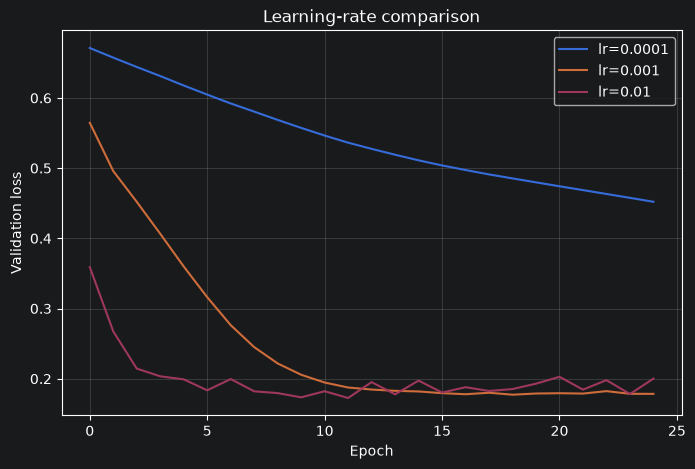

In [7]:
lr_histories = {}
for lr in [1e-4, 1e-3, 1e-2]:
    print(f"\n--- Adam learning rate: {lr:g} ---")
    torch.manual_seed(SEED)
    m = MLP().to(device)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    lr_histories[lr] = train_model(
        m, train_loader, val_loader, criterion, opt, epochs=25, device=device
    )

plt.figure(figsize=(8, 5))
for lr, h in lr_histories.items():
    plt.plot(h["val_loss"], label=f"lr={lr:g}")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Learning-rate comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 10. Optimizers: SGD, Momentum, RMSprop, Adam, and AdamW

### SGD
$$
\theta_{t+1} = \theta_t - \eta g_t
$$

### Momentum
$$
v_t = \beta v_{t-1} + g_t,\qquad
\theta_{t+1} = \theta_t - \eta v_t
$$

Momentum accumulates a moving direction and can reduce zig-zagging.

### RMSprop
$$
s_t = \rho s_{t-1} + (1-\rho)g_t^2
$$

RMSprop scales updates using a moving average of squared gradients.

### Adam
Adam tracks moving averages of gradients and squared gradients, with bias correction. It is a strong default for many tasks, but not always the best choice.

### AdamW
AdamW uses decoupled weight decay and is often preferred when explicitly applying weight decay with Adam-like optimization.

No optimizer is universally best. Learning rates should be tuned for each optimizer rather than assumed interchangeable.


--- SGD ---
Epoch 001/30 | train loss=0.5610 | val loss=0.5659 | train acc=0.731 | val acc=0.731
Epoch 010/30 | train loss=0.3531 | val loss=0.3572 | train acc=0.817 | val acc=0.822
Epoch 020/30 | train loss=0.1897 | val loss=0.2062 | train acc=0.938 | val acc=0.931
Epoch 030/30 | train loss=0.1501 | val loss=0.1793 | train acc=0.945 | val acc=0.908

--- SGD + Momentum ---
Epoch 001/30 | train loss=0.5066 | val loss=0.5112 | train acc=0.731 | val acc=0.731
Epoch 010/30 | train loss=0.1374 | val loss=0.1689 | train acc=0.942 | val acc=0.925
Epoch 020/30 | train loss=0.1367 | val loss=0.1876 | train acc=0.941 | val acc=0.922
Epoch 030/30 | train loss=0.1393 | val loss=0.2053 | train acc=0.942 | val acc=0.889

--- RMSprop ---
Epoch 001/30 | train loss=0.4146 | val loss=0.4193 | train acc=0.731 | val acc=0.731
Epoch 010/30 | train loss=0.1493 | val loss=0.1779 | train acc=0.937 | val acc=0.922
Epoch 020/30 | train loss=0.1361 | val loss=0.1797 | train acc=0.946 | val acc=0.914
Epoch 030/3

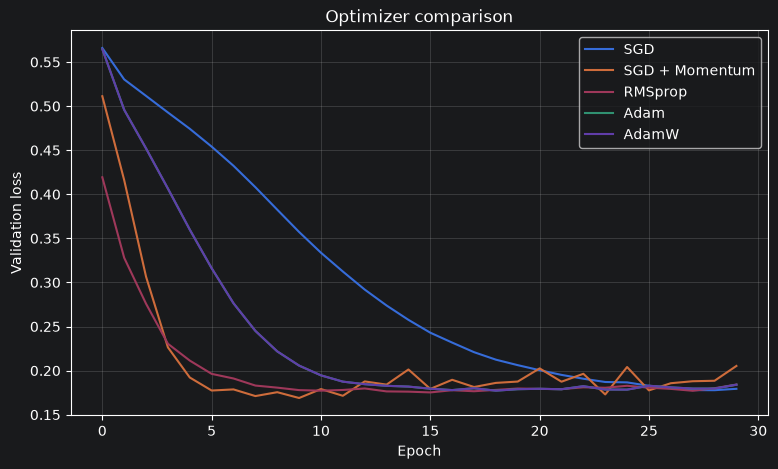

In [8]:
optimizer_factories = {
    "SGD": lambda p: torch.optim.SGD(p, lr=0.05),
    "SGD + Momentum": lambda p: torch.optim.SGD(p, lr=0.03, momentum=0.9),
    "RMSprop": lambda p: torch.optim.RMSprop(p, lr=1e-3),
    "Adam": lambda p: torch.optim.Adam(p, lr=1e-3),
    "AdamW": lambda p: torch.optim.AdamW(p, lr=1e-3, weight_decay=1e-3),
}
optimizer_results = {}
for name, factory in optimizer_factories.items():
    print(f"\n--- {name} ---")
    torch.manual_seed(SEED)
    m = MLP().to(device)
    opt = factory(m.parameters())
    h = train_model(m, train_loader, val_loader, criterion, opt,
                    epochs=30, device=device)
    optimizer_results[name] = {"model": m, "history": h}

plt.figure(figsize=(9, 5))
for name, result in optimizer_results.items():
    plt.plot(result["history"]["val_loss"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Optimizer comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 11. Learning-rate schedules

Schedulers change the learning rate during training. They can allow larger early updates and smaller later updates.

- `StepLR`: reduce the rate at fixed intervals.
- `ExponentialLR`: multiply the rate by a constant factor.
- `CosineAnnealingLR`: follow a cosine-shaped schedule.
- `ReduceLROnPlateau`: reduce the rate when a monitored metric stops improving.

For `ReduceLROnPlateau`, pass the monitored metric, often validation loss. Other schedulers are usually stepped after the epoch's optimizer updates in a conventional epoch-based loop.

Epoch 001/45 | train loss=0.4718 | val loss=0.4775 | train acc=0.731 | val acc=0.731
Epoch 010/45 | train loss=0.1363 | val loss=0.1782 | train acc=0.942 | val acc=0.917
Epoch 020/45 | train loss=0.1323 | val loss=0.1825 | train acc=0.943 | val acc=0.914
Epoch 030/45 | train loss=0.1318 | val loss=0.1810 | train acc=0.943 | val acc=0.911
Epoch 040/45 | train loss=0.1315 | val loss=0.1823 | train acc=0.945 | val acc=0.911


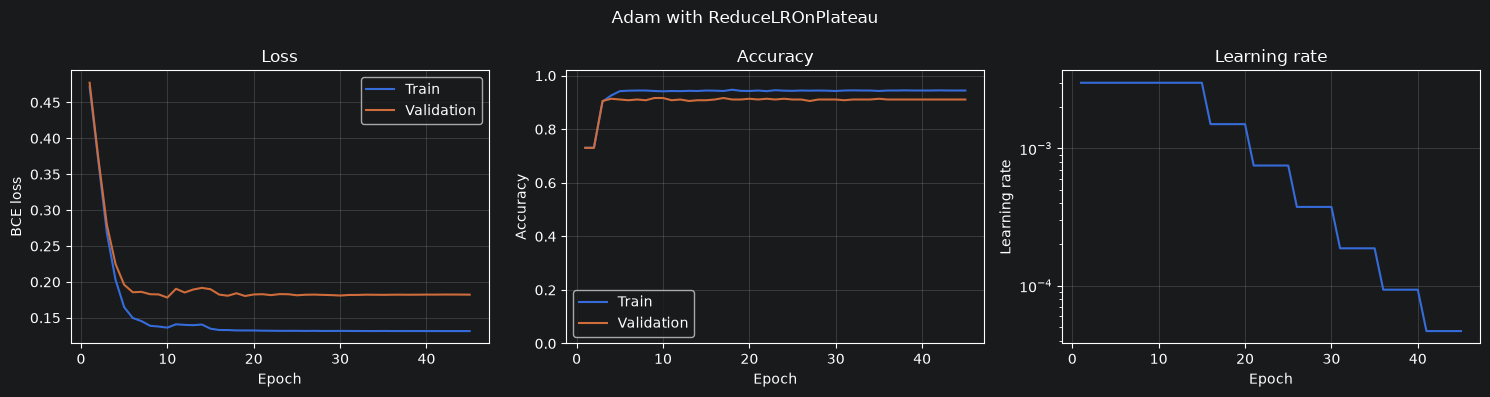

In [9]:
torch.manual_seed(SEED)
scheduled_model = MLP().to(device)
scheduled_optimizer = torch.optim.Adam(scheduled_model.parameters(), lr=3e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    scheduled_optimizer, mode="min", factor=0.5, patience=4, min_lr=1e-5
)
scheduled_history = train_model(
    scheduled_model, train_loader, val_loader, criterion, scheduled_optimizer,
    epochs=45, device=device, scheduler=scheduler
)
plot_history(scheduled_history, "Adam with ReduceLROnPlateau")

## 12. Underfitting, overfitting, and regularization

**Underfitting:** the model fails to learn useful structure from training data. Consider improving features, increasing capacity, training longer, or fixing optimization.

**Overfitting:** the model fits training-specific patterns that do not generalize. Training loss may keep decreasing while validation loss stops improving or rises.

Methods to improve generalization include:
- More representative training data.
- A smaller model.
- Weight decay.
- Dropout.
- Data augmentation, where appropriate.
- Early stopping.
- Correct data splits and leakage prevention.

Regularization is not always beneficial: too much can cause underfitting.


--- Baseline ---
Epoch 001/45 | train loss=0.5584 | val loss=0.5647 | train acc=0.731 | val acc=0.731
Epoch 010/45 | train loss=0.1842 | val loss=0.2057 | train acc=0.936 | val acc=0.919
Epoch 020/45 | train loss=0.1376 | val loss=0.1789 | train acc=0.943 | val acc=0.914
Epoch 030/45 | train loss=0.1357 | val loss=0.1840 | train acc=0.944 | val acc=0.906
Epoch 040/45 | train loss=0.1329 | val loss=0.1806 | train acc=0.942 | val acc=0.919

--- Dropout 0.25 ---
Epoch 001/45 | train loss=0.5620 | val loss=0.5684 | train acc=0.731 | val acc=0.731
Epoch 010/45 | train loss=0.2142 | val loss=0.2313 | train acc=0.925 | val acc=0.917
Epoch 020/45 | train loss=0.1573 | val loss=0.1884 | train acc=0.938 | val acc=0.917
Epoch 030/45 | train loss=0.1453 | val loss=0.1823 | train acc=0.942 | val acc=0.914
Epoch 040/45 | train loss=0.1443 | val loss=0.1822 | train acc=0.943 | val acc=0.919

--- Weight decay 1e-3 ---
Epoch 001/45 | train loss=0.5589 | val loss=0.5653 | train acc=0.731 | val acc=0.73

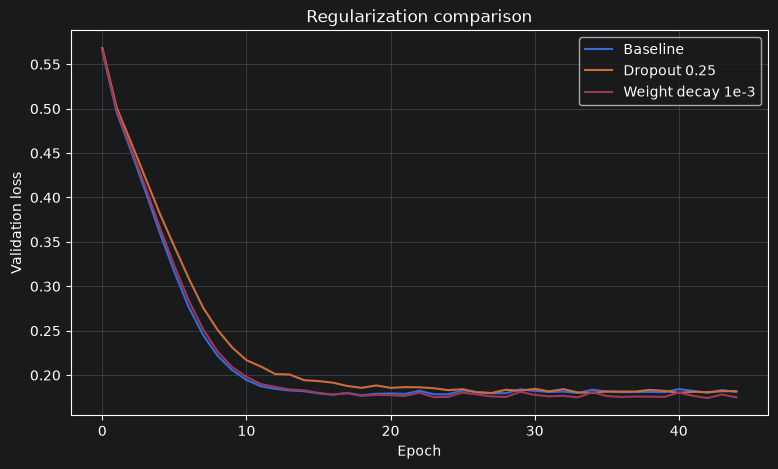

In [10]:
def train_regularized(dropout=0.0, weight_decay=0.0, epochs=45):
    # Compare dropout and weight decay while holding other settings fixed.
    torch.manual_seed(SEED)
    m = MLP(dropout=dropout).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=weight_decay)
    h = train_model(m, train_loader, val_loader, criterion, opt,
                    epochs=epochs, device=device)
    return m, h

regularization_runs = {}
settings = [
    ("Baseline", 0.0, 0.0),
    ("Dropout 0.25", 0.25, 0.0),
    ("Weight decay 1e-3", 0.0, 1e-3),
]
for label, dropout, decay in settings:
    print(f"\n--- {label} ---")
    m, h = train_regularized(dropout, decay)
    regularization_runs[label] = {"model": m, "history": h}

plt.figure(figsize=(9, 5))
for label, result in regularization_runs.items():
    plt.plot(result["history"]["val_loss"], label=label)
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Regularization comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 13. Early stopping and best checkpoints

Early stopping halts training when validation performance has not improved for a chosen number of epochs. It can reduce wasted computation and help avoid overfitting.

The helper below:
- monitors validation loss,
- saves a deep copy of the best model weights,
- stops after `patience` epochs without meaningful improvement,
- restores the best weights before returning.

Do not use test performance to decide when to stop.

Epoch 10: train=0.2146, val=0.2056
Epoch 20: train=0.1682, val=0.1779
Epoch 30: train=0.1670, val=0.1766
Early stopping at epoch 39; best epoch=27
Best epoch: 27 | best validation loss: 0.1755


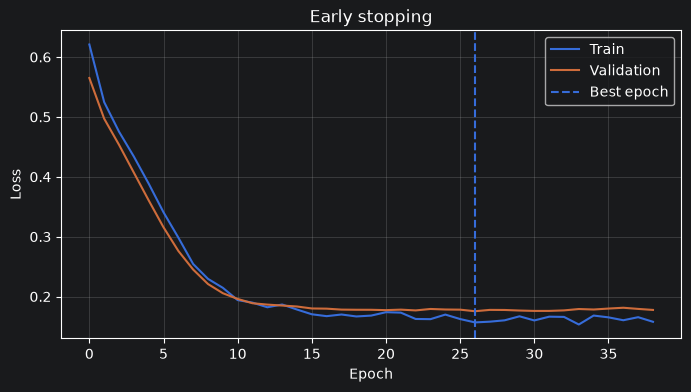

In [11]:
def train_with_early_stopping(model, train_loader, val_loader, criterion, optimizer,
                              epochs=100, patience=10, min_delta=1e-4, device=device):
    # Keep the weights associated with the best validation loss.
    best_loss = float("inf")
    best_epoch = 0
    best_state = copy.deepcopy(model.state_dict())
    stale_epochs = 0
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(epochs):
        model.train()
        total_loss, total_count = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * xb.size(0)
            total_count += xb.size(0)

        train_loss = total_loss / total_count
        val_loss, _ = evaluate_loss_and_accuracy(model, val_loader, criterion, device)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_loss - min_delta:
            best_loss = val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1

        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch + 1}: train={train_loss:.4f}, val={val_loss:.4f}")
        if stale_epochs >= patience:
            print(f"Early stopping at epoch {epoch + 1}; best epoch={best_epoch}")
            break

    model.load_state_dict(best_state)
    return model, history, best_epoch, best_loss


torch.manual_seed(SEED)
early_model = MLP(dropout=0.1).to(device)
early_optimizer = torch.optim.Adam(early_model.parameters(), lr=1e-3)
early_model, early_history, best_epoch, best_val_loss = train_with_early_stopping(
    early_model, train_loader, val_loader, criterion, early_optimizer,
    epochs=100, patience=12, device=device
)
print("Best epoch:", best_epoch, "| best validation loss:", round(best_val_loss, 4))

plt.figure(figsize=(8, 4))
plt.plot(early_history["train_loss"], label="Train")
plt.plot(early_history["val_loss"], label="Validation")
plt.axvline(best_epoch - 1, linestyle="--", label="Best epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Early stopping")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 14. Gradient norms and gradient clipping

Very large gradients can produce unstable updates; very small gradients can slow learning. Vanishing gradients are especially relevant in deep networks and some architecture/activation combinations.

Global norm clipping rescales gradients if their combined norm exceeds a threshold \(c\):

$$
g \leftarrow g \cdot \min\left(1,\frac{c}{\|g\|_2}\right)
$$

In PyTorch, `torch.nn.utils.clip_grad_norm_` modifies gradients in place. Clipping can stabilize updates, but it does not fix every cause of unstable training.

In [12]:
# Inspect gradient norms on one batch.
torch.manual_seed(SEED)
diagnostic_model = MLP().to(device)
diagnostic_optimizer = torch.optim.Adam(diagnostic_model.parameters(), lr=1e-3)
xb, yb = next(iter(train_loader))
xb, yb = xb.to(device), yb.to(device)

diagnostic_optimizer.zero_grad(set_to_none=True)
loss = criterion(diagnostic_model(xb), yb)
loss.backward()

grad_norm = torch.sqrt(sum(
    (p.grad.detach() ** 2).sum()
    for p in diagnostic_model.parameters() if p.grad is not None
))
print("Loss:", round(loss.item(), 5))
print("Gradient norm before clipping:", round(grad_norm.item(), 5))

nn.utils.clip_grad_norm_(diagnostic_model.parameters(), max_norm=1.0)
clipped_norm = torch.sqrt(sum(
    (p.grad.detach() ** 2).sum()
    for p in diagnostic_model.parameters() if p.grad is not None
))
print("Gradient norm after clipping:", round(clipped_norm.item(), 5))
diagnostic_optimizer.step()

Loss: 0.68471
Gradient norm before clipping: 0.39221
Gradient norm after clipping: 0.39221


## 15. Batch size: speed, memory, and gradient noise

- Smaller batches use less memory and give noisier gradient estimates.
- Larger batches may improve accelerator throughput but require more memory.
- Batch size changes the number of optimizer updates per epoch.
- A larger batch is not automatically better and may require learning-rate retuning.

When comparing batch sizes, decide whether the comparison is based on equal epochs, equal optimizer steps, or equal compute time. These are different experimental questions.


--- Batch size: 16 ---
Epoch 001/25 | train loss=0.4347 | val loss=0.4396 | train acc=0.731 | val acc=0.731
Epoch 010/25 | train loss=0.1362 | val loss=0.1738 | train acc=0.942 | val acc=0.919
Epoch 020/25 | train loss=0.1325 | val loss=0.1801 | train acc=0.944 | val acc=0.914

--- Batch size: 64 ---
Epoch 001/25 | train loss=0.5584 | val loss=0.5647 | train acc=0.731 | val acc=0.731
Epoch 010/25 | train loss=0.1842 | val loss=0.2057 | train acc=0.936 | val acc=0.919
Epoch 020/25 | train loss=0.1376 | val loss=0.1789 | train acc=0.943 | val acc=0.914

--- Batch size: 256 ---
Epoch 001/25 | train loss=0.6437 | val loss=0.6474 | train acc=0.731 | val acc=0.731
Epoch 010/25 | train loss=0.4567 | val loss=0.4621 | train acc=0.731 | val acc=0.731
Epoch 020/25 | train loss=0.3176 | val loss=0.3244 | train acc=0.840 | val acc=0.842


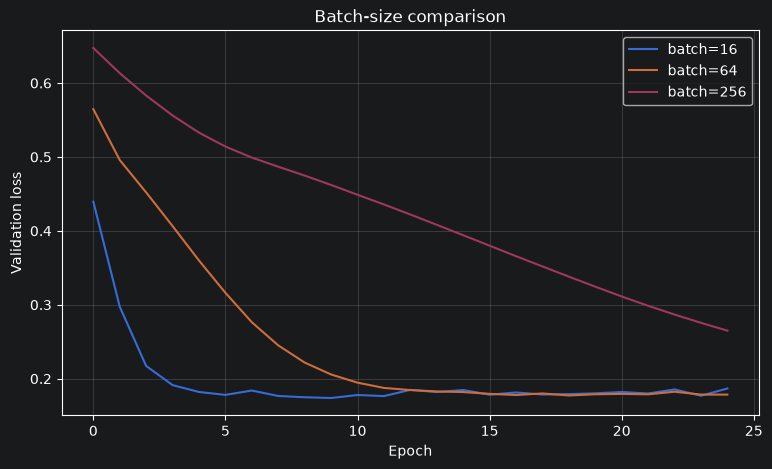

In [13]:
batch_results = {}
for bs in [16, 64, 256]:
    print(f"\n--- Batch size: {bs} ---")
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=bs, shuffle=True)
    torch.manual_seed(SEED)
    m = MLP().to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    batch_results[bs] = train_model(
        m, loader, val_loader, criterion, opt, epochs=25, device=device
    )

plt.figure(figsize=(9, 5))
for bs, h in batch_results.items():
    plt.plot(h["val_loss"], label=f"batch={bs}")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Batch-size comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 16. Evaluation beyond accuracy

Accuracy is the fraction of correct predictions at a selected threshold. It can be misleading for imbalanced classification.

- **Precision:** among predicted positives, how many are true positives?
- **Recall / sensitivity:** among actual positives, how many were detected?
- **Specificity:** among actual negatives, how many were correctly identified?
- **F1 score:** harmonic mean of precision and recall.
- **ROC-AUC:** ranking quality across classification thresholds.
- **Calibration:** whether predicted probabilities agree with observed frequencies.

A threshold of 0.5 is a convention, not a universal optimum. In clinical or scientific applications, thresholds should reflect the costs of false positives and false negatives and should be chosen without using test labels.

In [14]:
def binary_metrics_from_logits(logits, targets, threshold=0.5):
    # Compute common binary metrics from logits and 0/1 targets.
    probs = torch.sigmoid(logits).detach().cpu().numpy().ravel()
    y_true = targets.detach().cpu().numpy().astype(int).ravel()
    y_pred = (probs >= threshold).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
    return {
        "threshold": threshold, "accuracy": accuracy, "precision": precision,
        "recall": recall, "specificity": specificity, "f1": f1,
        "TP": tp, "TN": tn, "FP": fp, "FN": fn
    }

early_model.eval()
with torch.no_grad():
    val_logits = early_model(X_val.to(device))
metrics = binary_metrics_from_logits(val_logits, y_val)
for name, value in metrics.items():
    print(f"{name:>12}: {value:.4f}" if isinstance(value, float)
          else f"{name:>12}: {value}")

   threshold: 0.5000
    accuracy: 0.9194
   precision: 0.9432
      recall: 0.9468
 specificity: 0.8454
          f1: 0.9450
          TP: 249
          TN: 82
          FP: 15
          FN: 14


## 17. Visualize the decision boundary

For two input features, the decision-boundary plot shows predicted probability over a grid. The contour at \(0.5\) is the model's classification boundary for a threshold of 0.5.

A visually convincing boundary does not replace quantitative evaluation. Always inspect validation/test metrics and ask whether the data represent the intended real-world population.

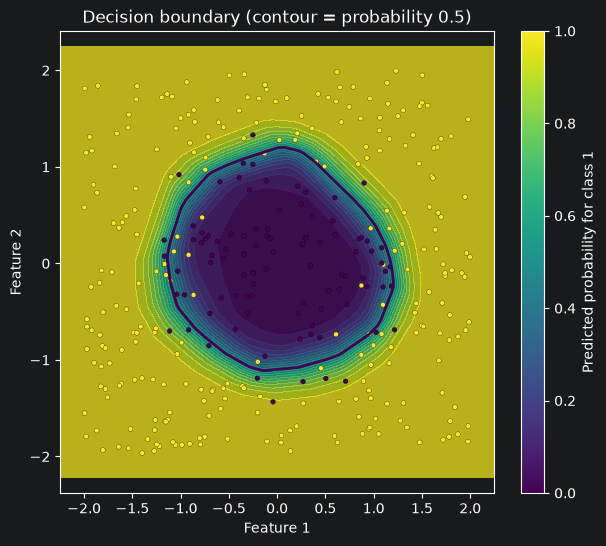

In [15]:
def plot_decision_boundary(model, X, y, device=device, resolution=250):
    # Evaluate probabilities over a grid of two-dimensional feature values.
    model.eval()
    x_min, x_max = X[:, 0].min().item() - 0.25, X[:, 0].max().item() + 0.25
    y_min, y_max = X[:, 1].min().item() - 0.25, X[:, 1].max().item() + 0.25
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, resolution),
                         np.linspace(y_min, y_max, resolution))
    grid = np.column_stack([xx.ravel(), yy.ravel()]).astype(np.float32)
    with torch.no_grad():
        grid_tensor = torch.tensor(grid, device=device)
        probs = torch.sigmoid(model(grid_tensor)).cpu().numpy().reshape(xx.shape)

    plt.figure(figsize=(7, 6))
    plt.contourf(xx, yy, probs, levels=20, alpha=0.75)
    plt.contour(xx, yy, probs, levels=[0.5], linewidths=2)
    plt.scatter(X[:, 0], X[:, 1], c=y.squeeze(), edgecolors="k",
                linewidths=0.2, s=12)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title("Decision boundary (contour = probability 0.5)")
    plt.colorbar(label="Predicted probability for class 1")
    plt.axis("equal")
    plt.show()

plot_decision_boundary(early_model, X_val, y_val, device=device)

## 18. Final test-set evaluation

Use the test set only after model and hyperparameter choices are complete. One split can be lucky or unlucky, so cross-validation or repeated splits may be useful for small datasets. The split strategy must respect the data structure; for example, medical images from the same patient should not be scattered across train and test sets.

In [16]:
test_loss, test_accuracy = evaluate_loss_and_accuracy(
    early_model, test_loader, criterion, device
)
early_model.eval()
with torch.no_grad():
    test_logits = early_model(X_test.to(device))
test_metrics = binary_metrics_from_logits(test_logits, y_test)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
for metric in ["precision", "recall", "specificity", "f1"]:
    print(f"{metric}: {test_metrics[metric]:.4f}")

Test loss: 0.1603
Test accuracy: 0.9361
precision: 0.9321
recall: 0.9849
specificity: 0.8000
f1: 0.9578


## 19. Save and load a checkpoint

A model `state_dict` stores learned parameters. To resume training faithfully, also save optimizer state, epoch, scheduler state if used, and configuration. A checkpoint does not contain the Python class definition, so recreate the same architecture before loading weights.

Only load checkpoint files you trust.

In [17]:
checkpoint_path = "training_optimization_checkpoint.pt"
checkpoint = {
    "model_state_dict": early_model.state_dict(),
    "optimizer_state_dict": early_optimizer.state_dict(),
    "best_epoch": best_epoch,
    "best_validation_loss": best_val_loss,
    "config": {"input_dim": 2, "hidden_dim": 32, "dropout": 0.1, "seed": SEED}
}
torch.save(checkpoint, checkpoint_path)
print("Saved:", checkpoint_path)

# Load only a checkpoint that you created or otherwise trust.
loaded = torch.load(checkpoint_path, map_location=device, weights_only=False)
restored_model = MLP(**{
    "input_dim": loaded["config"]["input_dim"],
    "hidden_dim": loaded["config"]["hidden_dim"],
    "dropout": loaded["config"]["dropout"]
}).to(device)
restored_model.load_state_dict(loaded["model_state_dict"])
restored_model.eval()
print("Restored model test metrics:",
      evaluate_loss_and_accuracy(restored_model, test_loader, criterion, device))

Saved: training_optimization_checkpoint.pt
Restored model test metrics: (0.16028093977106941, 0.9361111111111111)


## 20. Common mistakes and debugging

| Symptom | Possible cause | What to inspect |
|---|---|---|
| Loss does not change | Learning rate, labels, frozen parameters, missing update | Check gradients and `optimizer.step()` |
| Loss becomes `NaN` | Excessive learning rate, invalid data, unstable math | Check finite inputs, logits, and loss |
| Shape mismatch | Incompatible target/output dimensions | Print tensor shapes |
| Accuracy is stuck | Label convention, threshold, features, or loss mismatch | Inspect labels and predicted probabilities |
| Training good, validation poor | Overfitting or distribution shift | Check split design and regularization |
| Suspiciously high validation score | Leakage or duplicate examples | Split at the correct unit, e.g. patient |
| GPU out of memory | Batch/model too large or graph retention | Reduce batch size; avoid retaining graph tensors |
| Results vary between runs | Randomness or nondeterministic kernels | Set seeds and repeat experiments |
| Gradients are `None` | Disconnected graph or frozen parameters | Inspect `requires_grad`, `.detach()`, and forward pass |

For binary classification with `BCEWithLogitsLoss`, logits and floating-point targets commonly have matching shapes such as `(batch_size, 1)`.

In [18]:
# A compact debugging checklist for one batch.
xb, yb = next(iter(train_loader))
xb, yb = xb.to(device), yb.to(device)
logits = model(xb)
loss = criterion(logits, yb)
print("Input:", xb.shape, xb.dtype, xb.device)
print("Target:", yb.shape, yb.dtype, yb.device)
print("Output:", logits.shape)
print("Finite loss:", torch.isfinite(loss).item())

Input: torch.Size([64, 2]) torch.float32 cuda:0
Target: torch.Size([64, 1]) torch.float32 cuda:0
Output: torch.Size([64, 1])
Finite loss: True


## 21. A practical experimental protocol

1. Establish a baseline and record its configuration.
2. Confirm that the model can overfit a tiny clean subset; this is a useful pipeline sanity check.
3. Tune the learning rate before complicating the architecture.
4. Inspect training and validation curves.
5. Add regularization only when the evidence suggests it is needed.
6. Choose metrics appropriate to the task and class balance.
7. Use validation data for model selection.
8. Keep the test set untouched until final evaluation.
9. Repeat runs with multiple seeds when feasible.
10. Record software versions, data splits, hyperparameters, and seeds.

A model that cannot fit a tiny clean training subset may have a bug in its architecture, loss, labels, or training loop.

Epoch 001/60 | train loss=0.5289 | val loss=0.5289 | train acc=0.750 | val acc=0.750
Epoch 010/60 | train loss=0.2542 | val loss=0.2542 | train acc=0.906 | val acc=0.906
Epoch 020/60 | train loss=0.1896 | val loss=0.1896 | train acc=0.953 | val acc=0.953
Epoch 030/60 | train loss=0.1604 | val loss=0.1604 | train acc=0.969 | val acc=0.969
Epoch 040/60 | train loss=0.1456 | val loss=0.1456 | train acc=0.953 | val acc=0.953
Epoch 050/60 | train loss=0.1309 | val loss=0.1309 | train acc=0.953 | val acc=0.953
Epoch 060/60 | train loss=0.1151 | val loss=0.1151 | train acc=0.969 | val acc=0.969


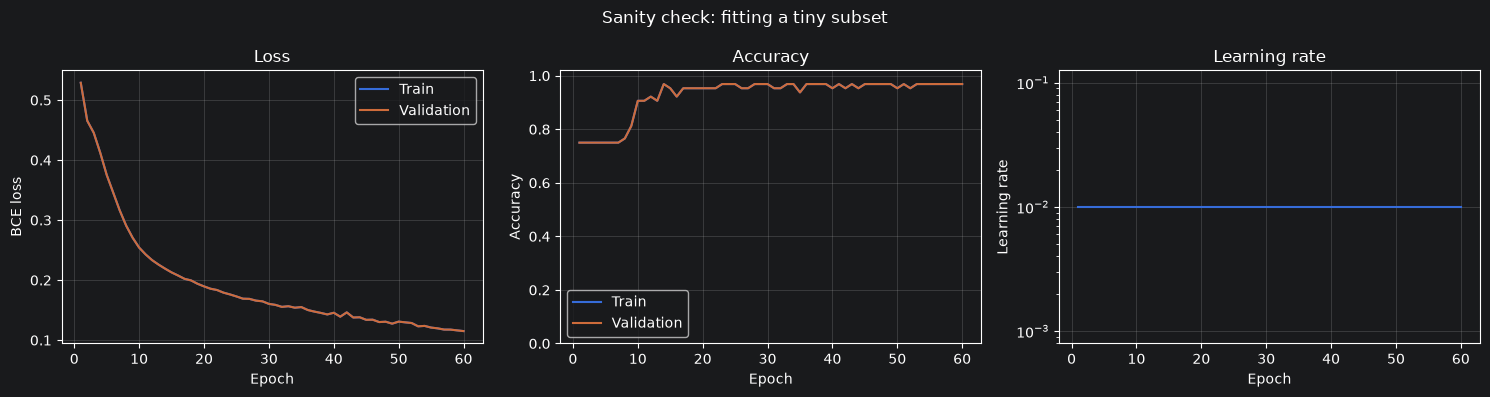

In [19]:
# Sanity check: intentionally train and evaluate on the same tiny subset.
tiny_X, tiny_y = X_train[:64], y_train[:64]
tiny_loader = DataLoader(TensorDataset(tiny_X, tiny_y), batch_size=16, shuffle=True)
torch.manual_seed(SEED)
tiny_model = MLP().to(device)
tiny_optimizer = torch.optim.Adam(tiny_model.parameters(), lr=1e-2)
tiny_history = train_model(
    tiny_model, tiny_loader, tiny_loader, criterion, tiny_optimizer,
    epochs=60, device=device
)
plot_history(tiny_history, "Sanity check: fitting a tiny subset")

## 22. Exercises

### Conceptual questions
1. Why is `optimizer.zero_grad()` needed in a standard training loop?
2. What is the difference between a logit and a probability?
3. Why should the test set not be used for early stopping?
4. How can training loss decrease while validation loss increases?
5. Why can a learning rate that is too large destabilize training?
6. Compare batch gradient descent with mini-batch gradient descent.
7. Why can accuracy be misleading for imbalanced data?
8. What does gradient clipping change, and what does it not fix?
9. Explain `model.train()` versus `model.eval()`.
10. Why save the best validation checkpoint instead of only the final epoch?

### Coding exercises
1. Compare hidden dimensions 8, 32, and 128.
2. Compare SGD learning rates `0.001`, `0.01`, and `0.1`.
3. Add `StepLR` and compare with a constant learning rate.
4. Try dropout values `0.0`, `0.2`, and `0.5`.
5. Compare AdamW weight decay values `1e-4`, `1e-3`, and `1e-2`.
6. Change the classification threshold to `0.3` and `0.7`; compare precision and recall.
7. Make the dataset imbalanced and explain why accuracy becomes less informative.
8. Record gradient norm across training steps.
9. Run three random seeds and report mean and standard deviation of validation accuracy.
10. Save and restore the best validation checkpoint.

### Challenge project
Compare at least three optimizers, three learning rates, and two regularization settings. Keep the test set untouched until you choose the configuration. Report validation metrics, best epoch, training time, learning curves, and limitations.

## 23. Quick reference

### Standard training step
```python
model.train()
for xb, yb in train_loader:
    xb, yb = xb.to(device), yb.to(device)
    optimizer.zero_grad(set_to_none=True)
    logits = model(xb)
    loss = criterion(logits, yb)
    loss.backward()
    optimizer.step()
```

### Evaluation
```python
model.eval()
with torch.no_grad():
    logits = model(xb)
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= 0.5).float()
```

### Optimizers
```python
torch.optim.SGD(model.parameters(), lr=0.01)
torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
torch.optim.RMSprop(model.parameters(), lr=1e-3)
torch.optim.Adam(model.parameters(), lr=1e-3)
torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
```

### Gradient clipping
```python
loss.backward()
torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
optimizer.step()
```

**Remember:** `backward()` computes gradients; `step()` updates parameters. Clear gradients, use logits with `BCEWithLogitsLoss`, validate without gradients, and keep test data separate from model selection.

## 24. Key takeaways and next step

Training is more than calling `optimizer.step()`.

- Learning rate controls update scale.
- Mini-batches provide practical gradient estimates.
- Optimizers differ in how they use current and historical gradients.
- Schedulers can improve late-stage optimization.
- Regularization and early stopping can improve generalization.
- Gradient clipping can stabilize unusually large updates.
- Curves and suitable metrics reveal more than one final score.
- Reliable evaluation depends on leakage-free splits and controlled experiments.

**Suggested next notebook:** `06 — Convolutional Neural Networks (CNNs)`, covering convolution, filters, channels, padding, stride, pooling, feature maps, PyTorch CNNs, and an image-classification experiment.